# Klassificatie kleding afbeeldingen


#### Inhoud (volgends opdracht, dit kan later weg, meer voor overzicht)

- Definieer het probleem
- Verzamel de data
- Laad de data in
- Prepareer de data # slaan we over is al gedaan
- Visualiseer de data
- Splits de data
- Train het model met de trainingsdata
- Voorspel met het model de testdata
- Evalueer het model

- Deel 2: Foto van jezelf

#### Definieer het probleem

We willen een neuraal netwerk trainen dat van een afbeelding kan voorspellen op kleding type. 


#### Verzamel de data & Laad data in

Dataset komt van deze repo: https://github.com/zalandoresearch/fashion-mnist/tree/master

In de map "data/fashion" staan 4 datasets (t10k-images-idx3-ubyte,  t10k-labels-idx1-ubyte,  train-images-idx3-ubyte,  train-labels-idx1-ubyte). 
Er is al train data, dus dat hoeven wij niet meer aan te maken. 





In [1]:
import numpy as np

# headerbytes overslaan met offset
X_train = np.fromfile("train-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28) # 28 pixels stond in beschrijving
y_train = np.fromfile("train-labels-idx1-ubyte", dtype=np.uint8, offset=8)

print("Aantal afbeeldingen:", X_train.shape)  # hoofdletter X want matrix!!
print("Labels van eerste 10 afbeeldingen:", y_train[:10])



Aantal afbeeldingen: (60000, 28, 28)
Labels van eerste 10 afbeeldingen: [9 0 0 3 0 2 7 2 5 5]


In [2]:
# test data inladen 

X_test = np.fromfile("t10k-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
y_test = np.fromfile("t10k-labels-idx1-ubyte", dtype=np.uint8, offset=8)

print("Aantal testafbeeldingen:", X_test.shape)

Aantal testafbeeldingen: (10000, 28, 28)


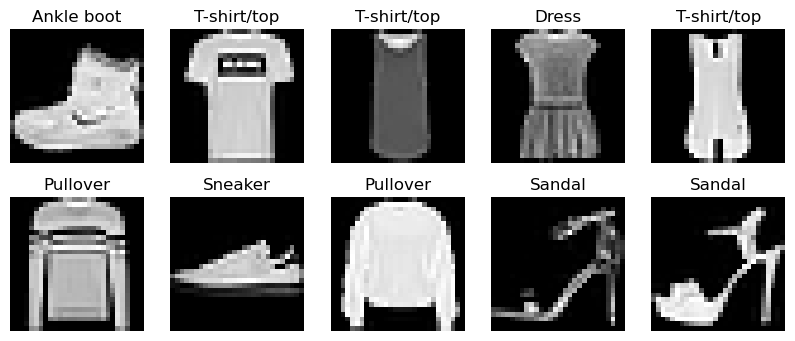

In [3]:
import matplotlib.pyplot as plt

# labels 0 t/m 9 omzetten naar namen (volgorde uit README van de repo)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Eerste 10 afbeeldingen tonen
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()

#### Prepareer de data



In [4]:
from sklearn.model_selection import train_test_split

images = np.fromfile("t10k-images-idx3-ubyte", dtype=np.uint8, offset=16).reshape(-1, 28, 28)
labels = np.fromfile("t10k-labels-idx1-ubyte", dtype=np.uint8, offset=8)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

x_train, x_test, y_train, y_test = train_test_split(
    images / 255.0, labels, test_size=0.2, random_state=42, stratify=labels
)

print(x_train.shape, x_test.shape)

(8000, 28, 28) (2000, 28, 28)


In [5]:
# pixels van 0-255 naar 0-1, neuraal netwerk leert beter met kleine getallen
X_train = X_train / 255.0
X_test = X_test / 255.0

print("min:", X_train.min(), "max:", X_train.max())

min: 0.0 max: 1.0


Met grote inputwaarden worden de berekeningen in het netwerk ook groot en dan leert het model trager en minder stabiel. 
Test data moeten we natuurlijk niet vergeten.